# Practical - 10

## Step 1 — Data input

In [2]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("orders.csv", sep=";")

print("Dataset loaded successfully!")
print("First 5 rows:")
display(df.head())

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

Saving orders.csv to orders.csv
Dataset loaded successfully!
First 5 rows:


,order_id,order_date,customer_id,product_category,product_name,quantity,sales
0,CAF-10319,23/06/2024,K0091,Beverages,Masala Chai,2.0,100.0
1,CAF-9822,27/10/2024,K0488,Desserts,Chocolate Brownie,3.0,405.0
2,CAF-10147,03/12/2024,K0117,Main Course,Veg Biryani,2.0,532.0
3,CAF-9281,11/04/2023,K0223,Beverages,Fresh Lime Soda,4.0,320.0
4,CAF-10694,16/01/2024,K0513,Main Course,Margherita Pizza,1.0,332.5


Dataset shape: (4108, 7)
Column names: ['order_id', 'order_date', 'customer_id', 'product_category', 'product_name', 'quantity', 'sales']


## Step 2 — Data cleaning

In [3]:
# Remove duplicate rows
df = df.drop_duplicates()

# Convert order_date into a date format
df["order_date"] = pd.to_datetime(
    df["order_date"], dayfirst=True, errors="coerce"
)

# Convert numeric columns
df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce")
df["sales"] = pd.to_numeric(df["sales"], errors="coerce")

# Remove rows missing essential information
df = df.dropna(
    subset=["order_id", "order_date", "quantity", "sales"]
)

print("Data cleaning completed!")
print("Rows after cleaning:", len(df))
display(df.head())

Data cleaning completed!
Rows after cleaning: 4021


,order_id,order_date,customer_id,product_category,product_name,quantity,sales
0,CAF-10319,2024-06-23,K0091,Beverages,Masala Chai,2.0,100.0
1,CAF-9822,2024-10-27,K0488,Desserts,Chocolate Brownie,3.0,405.0
2,CAF-10147,2024-12-03,K0117,Main Course,Veg Biryani,2.0,532.0
3,CAF-9281,2023-04-11,K0223,Beverages,Fresh Lime Soda,4.0,320.0
4,CAF-10694,2024-01-16,K0513,Main Course,Margherita Pizza,1.0,332.5


## Step 3 — Data analysis

In [4]:
print("TOTAL SALES:", round(df["sales"].sum(), 2))
print("TOTAL ORDERS:", df["order_id"].nunique())
print("TOTAL QUANTITY SOLD:", df["quantity"].sum())
print("AVERAGE ORDER SALES:", round(df["sales"].mean(), 2))

print("\nSales by Product Category:")
category_sales = df.groupby(
    "product_category"
)["sales"].sum().sort_values(ascending=False)

display(category_sales.to_frame())

print("\nTop 5 Products by Sales:")
product_sales = df.groupby(
    "product_name"
)["sales"].sum().sort_values(ascending=False)

display(product_sales.head(5).to_frame())

TOTAL SALES: 1962555.0
TOTAL ORDERS: 1699
TOTAL QUANTITY SOLD: 10057.0
AVERAGE ORDER SALES: 488.08

Sales by Product Category:


,sales
product_category,
Main Course,962629.5
Starters,487071.0
Beverages,312062.5
Desserts,200792.0



Top 5 Products by Sales:


,sales
product_name,
Butter Chicken,378609.0
Margherita Pizza,325412.5
Veg Biryani,258608.0
Chicken Wings,210352.0
Paneer Tikka,167063.0


## Step 4 — Check null and missing values

In [5]:
print("Missing Values in Each Column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nInvalid or Missing Dates:")
print(df["order_date"].isna().sum())

print("\nDataset Information:")
df.info()

Missing Values in Each Column:


,Missing Values
order_id,0
order_date,0
customer_id,0
product_category,0
product_name,0
quantity,0
sales,0



Total Missing Values:
0

Duplicate Rows:
0

Invalid or Missing Dates:
0

Dataset Information:
<class 'pandas.DataFrame'>
Index: 4021 entries, 0 to 4107
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          4021 non-null   str           
 1   order_date        4021 non-null   datetime64[us]
 2   customer_id       4021 non-null   str           
 3   product_category  4021 non-null   str           
 4   product_name      4021 non-null   str           
 5   quantity          4021 non-null   float64       
 6   sales             4021 non-null   float64       
dtypes: datetime64[us](1), float64(2), str(4)
memory usage: 251.3 KB


## Step 5 — Sales trend and patterns

Monthly Sales:


,Total Sales
Month,
2023-01,82055.5
2023-02,88640.0
2023-03,68004.5
2023-04,84386.5
2023-05,58598.0
2023-06,48071.5
2023-07,91203.5
2023-08,95695.5
2023-09,98342.0


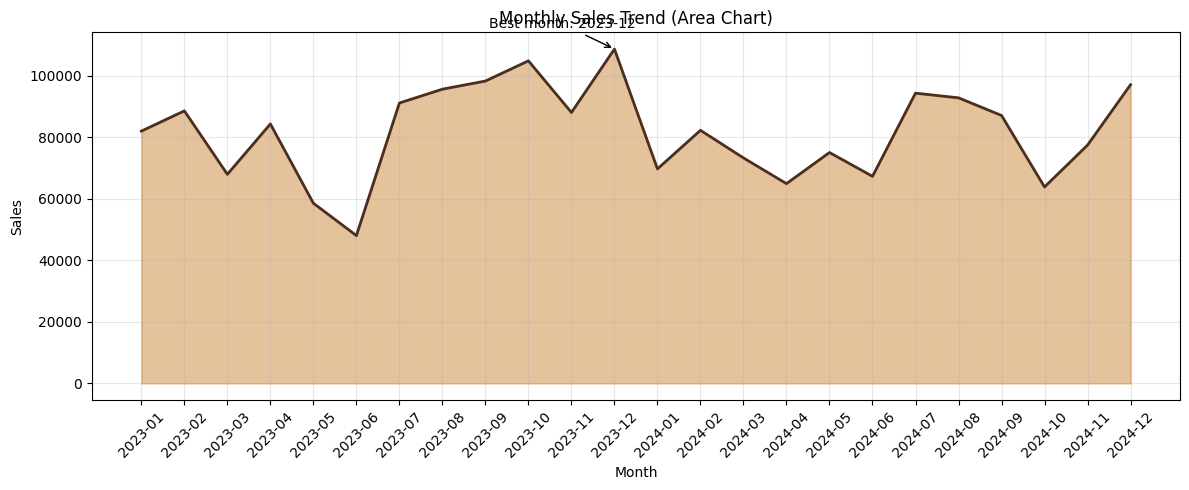

Average Quantity per Order: 2.5
Maximum Quantity in an Order: 4.0
Minimum Quantity in an Order: 1.0


In [6]:
import matplotlib.pyplot as plt

# Extract month from order date
df["Month"] = df["order_date"].dt.to_period("M").astype(str)

# Monthly sales analysis
monthly_sales = df.groupby("Month")["sales"].sum()

print("Monthly Sales:")
display(monthly_sales.to_frame("Total Sales"))

# Plot monthly sales as an area chart
plt.figure(figsize=(12, 5))
plt.fill_between(monthly_sales.index, monthly_sales.values, color="#C8873A", alpha=0.5)
plt.plot(monthly_sales.index, monthly_sales.values, color="#4B2E1E", linewidth=2)

# Mark the best month
best_month = monthly_sales.idxmax()
plt.annotate("Best month: " + best_month,
             xy=(best_month, monthly_sales.max()),
             xytext=(-90, 15), textcoords="offset points",
             arrowprops=dict(arrowstyle="->"))

plt.title("Monthly Sales Trend (Area Chart)")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Study order quantities
print("Average Quantity per Order:", round(df["quantity"].mean(), 2))
print("Maximum Quantity in an Order:", df["quantity"].max())
print("Minimum Quantity in an Order:", df["quantity"].min())

### Step 5.1 — Sales share by product category (pie chart)

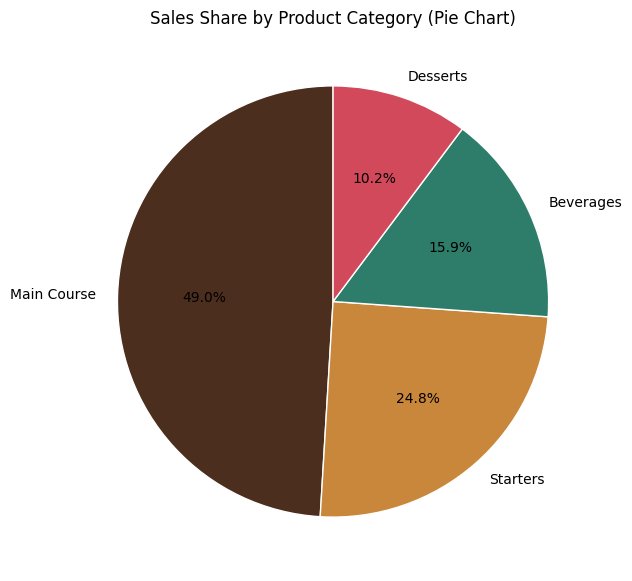

In [7]:
# Total sales for every product category
category_sales = df.groupby("product_category")["sales"].sum().sort_values(ascending=False)

# Pie chart with percentage labels
plt.figure(figsize=(7, 7))
plt.pie(
    category_sales.values,
    labels=category_sales.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#4B2E1E", "#C8873A", "#2E7D6B", "#D1495B"],
    wedgeprops={"edgecolor": "white"}
)
plt.title("Sales Share by Product Category (Pie Chart)")
plt.show()

### Step 5.2 — Sales by day of the week (column chart)

Sales by Day of the Week:


,Total Sales
Weekday,
Mon,226411.5
Tue,219745.0
Wed,247017.5
Thu,231201.0
Fri,315465.0
Sat,381170.5
Sun,341544.5


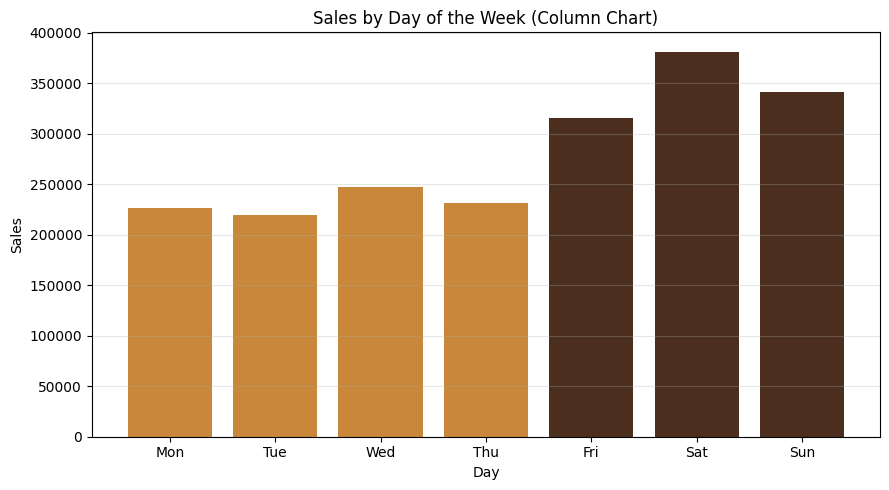

In [8]:
# Day name of every order
df["Weekday"] = df["order_date"].dt.day_name().str[:3]

# Total sales for each day, in week order
week_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday_sales = df.groupby("Weekday")["sales"].sum().reindex(week_order)

print("Sales by Day of the Week:")
display(weekday_sales.to_frame("Total Sales"))

# Column chart: Friday to Sunday in a darker colour
colors = ["#C8873A"] * 4 + ["#4B2E1E"] * 3
plt.figure(figsize=(9, 5))
plt.bar(weekday_sales.index, weekday_sales.values, color=colors)
plt.title("Sales by Day of the Week (Column Chart)")
plt.xlabel("Day")
plt.ylabel("Sales")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Step - 6 Power BI Dashboard

1. Imported the orders.csv dataset into Power BI.
2. Designed the dashboard with a dark coffee-brown title banner and a cream page background.
3. Created four cards on the left side: Total Sales, Total Orders, Average Order Value and Units Sold.
4. Added an area chart to analyze monthly sales trends.
5. Created a pie chart to compare sales by product category.
6. Added a column chart to compare sales by day of the week.
7. Applied colors, formatted the charts, and arranged all visuals to create a clean, attractive dashboard.